# 03 · RQ1 · Hubs: tài khoản fan-in và fan-out

**Câu hỏi nghiên cứu.** Rửa tiền có tập trung ở tài khoản nhận tiền từ (*fan-in*) hoặc chuyển tiền cho (*fan-out*) rất nhiều đối tác **trong thời gian ngắn** không? Cửa sổ thời gian có thêm thông tin so với bậc (*degree*) đếm trên cả đoạn (B3) không?

Notebook đọc đầu ra của `01_eda.ipynb` và `02_graph.ipynb`, ghi mọi kết quả vào `reports/rq1/`.

| Bước | Cách làm | Căn cứ |
|---|---|---|
| Đoạn | dev (60% giao dịch đầu của kỳ chính) / test (phần còn lại) / đuôi, đọc từ `analysis_period.json` | Đuôi gần như toàn giao dịch rửa tiền, chỉ báo cáo độ nhạy |
| Điểm | fan-in / fan-out = số đối tác ACH phân biệt lớn nhất trong cửa sổ trượt đóng $[t-W, t]$, $W$ = 24h, 48h (96h: độ nhạy) | Altman et al. (2023) |
| Đối chứng | **B1** = chọn ngẫu nhiên trong ứng viên; **B3** = số đối tác phân biệt trong cả đoạn, cùng hướng, cùng cách chuẩn hóa, cùng số cảnh báo | Starnini et al. (2021) |
| Nhóm đối chiếu | loại chủ thể × ngũ phân vị số giao dịch ACH/ngày (ngưỡng chốt trên dev), gộp nhóm < 100 tài khoản | Bolton & Hand (2001) |
| Burstiness | hệ số $A_n$ cho chuỗi hữu hạn (phụ lục) | Goh & Barabási (2008); Kim & Jo (2016) |
| Chọn biến thể | 8 biến thể (2 hướng × 24/48h × thô / nhóm đối chiếu). Chọn **trên dev** theo AP, ghi lựa chọn kèm hash **trước** khi tính số trên test | |
| Đánh giá | top 0,1% / 0,5% / 1% ứng viên; precision, khoảng Wilson 95%, recall, lift; cấp tài khoản và cấp giao dịch | Saito & Rehmsmeier (2015); Wilson (1927) |
| Kết luận | **Đào sâu** nếu thắng B1 (cận dưới Wilson > tỷ lệ nền) **và** B3 ở ≥ 2/3 mức trên test, và cũng vậy trên dev; **Điều chỉnh** nếu chỉ thắng B1; **Dừng** nếu không thắng B1 hoặc test có < 20 tài khoản dương | |

**Đồng hạng.** Điểm là số nguyên nhỏ (bậc ra ACH lớn nhất chỉ 17), nên ngưỡng `k` thường cắt ngang một nhóm lớn tài khoản cùng điểm. Precision khi đó phụ thuộc vào cách bốc thăm trong nhóm. Vì vậy mỗi dòng kết quả ghi ba thứ: precision với seed cố định (`precision`), **precision kỳ vọng khi bốc thăm ngẫu nhiên trong nhóm đồng hạng** (`precision_expected`, tính chính xác, không lấy mẫu), và số tài khoản được chọn nhờ bốc thăm. So sánh với baseline và kết luận dùng `precision_expected`.

## 1. Đầu vào và cấu hình

In [1]:
import hashlib
import json
import math
import os
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

GRAPH_REL = Path("data") / "processed" / "graph" / "graph_edges.parquet"


def find_project_root():
    """HI_SMALL_ROOT nếu đã đặt; nếu không, tìm thư mục chứa đầu ra của notebook 01–02."""
    if os.environ.get("HI_SMALL_ROOT"):
        return Path(os.environ["HI_SMALL_ROOT"]).expanduser()
    here = Path.cwd()
    for folder in (Path("/kaggle/working"), here, here.parent,
                   here / "IBM_HI_Small_EDA", here.parent / "IBM_HI_Small_EDA"):
        if (folder / GRAPH_REL).is_file():
            return folder
    raise FileNotFoundError(f"Không tìm thấy {GRAPH_REL}. Chạy 01_eda.ipynb và 02_graph.ipynb trước, "
                            "hoặc đặt biến môi trường HI_SMALL_ROOT.")


ROOT = find_project_root().resolve()
ACCOUNTS_FILE = (Path(os.environ["HI_SMALL_ACCOUNTS"]).expanduser() if os.environ.get("HI_SMALL_ACCOUNTS")
                 else next((f / "HI-Small_accounts.csv" for f in (ROOT / "data" / "raw", ROOT, ROOT.parent)
                            if (f / "HI-Small_accounts.csv").is_file()), ROOT / "HI-Small_accounts.csv"))
EDGES_FILE = ROOT / GRAPH_REL
NODES_FILE = ROOT / "data" / "processed" / "graph" / "graph_nodes.parquet"
TXN_FILE = ROOT / "data" / "processed" / "hi_small_graph_transactions.parquet"
REMOVED_FILE = ROOT / "data" / "processed" / "hi_small_removed_transactions.parquet"
PERIOD_FILE = ROOT / "reports" / "tables" / "analysis_period.json"
OUT = ROOT / "reports" / "rq1"
OUT.mkdir(parents=True, exist_ok=True)

# Cấu hình được băm vào hash của lựa chọn trên dev: không sửa sau khi đã chốt.
CFG = {
    "windows_main_h": [24, 48],
    "windows_sensitivity_h": [96],
    "directions": ["in", "out"],
    "budgets": [0.001, 0.005, 0.01],
    "seed": 42,
    "stability_seeds": list(range(10)),
    "activity_bins": 5,
    "min_peer_size": 100,
    "min_burst_intervals": 5,
    "min_positives": 20,
    "min_budgets_to_win": 2,
    "candidate_rule": "account with >= 1 ACH transaction (sent or received) in the segment",
    "positive_rule": "account is sender or receiver of >= 1 laundering transaction of any format "
                     "(self-loops and duplicates included) in the segment",
}

need = {TXN_FILE: "01_eda.ipynb", REMOVED_FILE: "01_eda.ipynb", PERIOD_FILE: "01_eda.ipynb",
        EDGES_FILE: "02_graph.ipynb", NODES_FILE: "02_graph.ipynb"}
missing = [f"  - {f} → chạy {nb}" for f, nb in need.items() if not f.is_file()]
if missing:
    raise FileNotFoundError("Thiếu đầu vào:\n" + "\n".join(missing))
print(f"Thư mục dự án: {ROOT}")
print(f"Kết quả ghi vào: {OUT}")
print(f"File accounts: {ACCOUNTS_FILE if ACCOUNTS_FILE.is_file() else 'không thấy'}")

period = json.loads(PERIOD_FILE.read_text(encoding="utf-8"))
SEGMENTS = ["dev", "test", "tail"]
seg_bounds_ts = [pd.Timestamp(period[k]) for k in ("main_start", "dev_end", "main_end", "data_end")]
seg_bounds = np.array([int(t.timestamp()) for t in seg_bounds_ts], dtype=np.int64)
seg_days = np.diff(seg_bounds) / 86400
display(pd.DataFrame({"đoạn": SEGMENTS, "bắt đầu": seg_bounds_ts[:-1], "kết thúc (không gồm)": seg_bounds_ts[1:],
                      "số ngày": seg_days.round(2)}))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
db = duckdb.connect()
_ = db.execute("SET threads = 4")
# Giới hạn RAM của DuckDB; phần vượt mức được ghi tạm ra đĩa thay vì làm sập kernel.
DUCKDB_TMP = ROOT / "data" / "duckdb_tmp"
DUCKDB_TMP.mkdir(parents=True, exist_ok=True)
_ = db.execute(f"SET memory_limit = '{os.environ.get('HI_SMALL_DUCKDB_MEMORY', '2GB')}'")
_ = db.execute(f"SET temp_directory = '{DUCKDB_TMP.as_posix()}'")

Thư mục dự án: D:\KLTN
Kết quả ghi vào: D:\KLTN\reports\rq1
File accounts: D:\KLTN\HI-Small_accounts.csv


,đoạn,bắt đầu,kết thúc (không gồm),số ngày
0,dev,2022-09-01 00:00:00,2022-09-06 13:00:00,5.54
1,test,2022-09-06 13:00:00,2022-09-11 00:00:00,4.46
2,tail,2022-09-11 00:00:00,2022-09-18 16:19:00,7.68


## 2. Tập giao dịch ACH (chưa đọc nhãn)

Lấy mọi cạnh ACH từ đầu kỳ chính đến hết dữ liệu, gắn mỗi cạnh vào đoạn dev / test / đuôi theo thời điểm.

In [2]:
edges = db.execute("""
    SELECT transaction_id, source_id, target_id, timestamp_s
    FROM read_parquet(?) WHERE payment_format = 'ACH' AND timestamp_s >= ?
    ORDER BY timestamp_s, transaction_id
""", [str(EDGES_FILE), int(seg_bounds[0])]).df()
nodes = db.execute("SELECT node_id, account_key, bank_id, account_id FROM read_parquet(?) ORDER BY node_id",
                   [str(NODES_FILE)]).df()
N_NODES = len(nodes)
src = edges.source_id.to_numpy(np.int64)
dst = edges.target_id.to_numpy(np.int64)
ts = edges.timestamp_s.to_numpy(np.int64)
edge_seg = np.searchsorted(seg_bounds, ts, side="right") - 1      # 0 dev, 1 test, 2 đuôi
print(f"Giao dịch ACH: {len(edges):,}; tài khoản trong đồ thị: {N_NODES:,}")
display(pd.Series(edge_seg).map(dict(enumerate(SEGMENTS))).value_counts().reindex(SEGMENTS)
        .rename("giao dịch ACH").to_frame())

Giao dịch ACH: 529,446; tài khoản trong đồ thị: 422,734


,giao dịch ACH
dev,298120
test,230611
tail,715


## 3. Fan-in và fan-out trong cửa sổ trượt

Với tài khoản $v$ và mỗi thời điểm giao dịch $t$ của nó, đếm số đối tác phân biệt có ít nhất một giao dịch trong $[t-W, t]$. Cửa sổ **không vượt qua đầu đoạn**, để fan và B3 nhìn cùng một lượng dữ liệu và nhãn cũng tính trong cùng đoạn. Các giao dịch cùng phút được thêm cùng lúc trước khi đếm. Điểm của $v$ trong một đoạn là **giá trị lớn nhất** trên các cửa sổ kết thúc trong đoạn; `end` là thời điểm sớm nhất đạt giá trị đó, dùng để truy lại giao dịch.

Ô dưới kiểm tra hàm trên ba ví dụ nhỏ, ví dụ: A nhận 5 giao dịch từ B và 1 từ C trong 24h thì fan-in = 2.

In [3]:
def sliding_peak(center, counterpart, t, window_s, bounds, n_nodes):
    """Số đối tác phân biệt lớn nhất trong [t - W, t], theo từng tài khoản và từng đoạn."""
    order = np.lexsort((t, center))
    c, p, tt = center[order], counterpart[order], t[order]
    seg = np.searchsorted(bounds, tt, side="right") - 1
    n_seg = len(bounds) - 1
    peak = np.zeros(n_nodes * n_seg, dtype=np.int64)
    end = np.full(n_nodes * n_seg, -1, dtype=np.int64)
    if len(c) == 0:
        return peak.reshape(n_nodes, n_seg), end.reshape(n_nodes, n_seg)
    starts = np.flatnonzero(np.r_[True, c[1:] != c[:-1]])
    stops = np.r_[starts[1:], len(c)]
    p_l, t_l, s_l, c_l = p.tolist(), tt.tolist(), seg.tolist(), c.tolist()
    b_l = bounds.tolist()
    pk, en = peak.tolist(), end.tolist()
    for g0, g1 in zip(starts.tolist(), stops.tolist()):
        base = c_l[g0] * n_seg
        counts = {}
        left = i = g0
        while i < g1:
            ti = t_l[i]
            j = i
            while j < g1 and t_l[j] == ti:
                q = p_l[j]
                counts[q] = counts.get(q, 0) + 1
                j += 1
            s = s_l[i]
            lo = ti - window_s
            if 0 <= s < n_seg and b_l[s] > lo:
                lo = b_l[s]          # cửa sổ không vượt qua đầu đoạn
            while t_l[left] < lo:
                q = p_l[left]
                k = counts[q] - 1
                if k:
                    counts[q] = k
                else:
                    del counts[q]
                left += 1
            if 0 <= s < n_seg:
                d = len(counts)
                if d > pk[base + s]:
                    pk[base + s] = d
                    en[base + s] = ti
            i = j
    return np.array(pk).reshape(n_nodes, n_seg), np.array(en).reshape(n_nodes, n_seg)


# A(0) nhận 5 lần từ B(1) và 1 lần từ C(2) trong 24h → fan-in = 2.
_c = np.array([0, 0, 0, 0, 0, 0]); _p = np.array([1, 1, 1, 1, 1, 2])
_t = np.array([0, 60, 120, 180, 240, 3600]) + 1000
_pk, _en = sliding_peak(_c, _p, _t, 24 * 3600, np.array([0, 10**9]), 3)
assert _pk[0, 0] == 2 and _en[0, 0] == 4600, (_pk, _en)
# Cửa sổ đóng bên trái: cạnh cách t đúng W vẫn được tính.
_pk, _ = sliding_peak(np.array([0, 0]), np.array([1, 2]), np.array([0, 3600]), 3600, np.array([0, 10**9]), 3)
assert _pk[0, 0] == 2
# Cửa sổ không với sang đoạn trước.
_pk, _ = sliding_peak(np.array([0, 0, 0]), np.array([1, 2, 3]), np.array([10, 20, 110]), 3600,
                      np.array([0, 100, 10**9]), 3)
assert _pk[0, 0] == 2 and _pk[0, 1] == 1, _pk
print("Ba ví dụ kiểm tra đều đúng.")

ALL_WINDOWS = CFG["windows_main_h"] + CFG["windows_sensitivity_h"]
fan = {}
t0 = time.time()
for direction in CFG["directions"]:
    center, cp = (dst, src) if direction == "in" else (src, dst)
    for W in ALL_WINDOWS:
        fan[(direction, W)] = sliding_peak(center, cp, ts, W * 3600, seg_bounds, N_NODES)
        print(f"fan_{direction}_{W}h xong ({time.time() - t0:.0f}s)")

Ba ví dụ kiểm tra đều đúng.
fan_in_24h xong (3s)
fan_in_48h xong (5s)
fan_in_96h xong (7s)
fan_out_24h xong (10s)
fan_out_48h xong (14s)
fan_out_96h xong (19s)


## 4. B3, mức hoạt động, nhóm đối chiếu và burstiness

- **B3** = số đối tác phân biệt trong cả đoạn, cùng hướng. Ví dụ: A nhận từ 30 tài khoản trong cả đoạn nhưng nhiều nhất 8 trong 24h → B3_in = 30, fan_in_24h = 8.
- **Ứng viên** của một đoạn = tài khoản có ít nhất 1 giao dịch ACH trong đoạn.
- **Nhóm đối chiếu** = loại chủ thể (từ `HI-Small_accounts.csv`) × ngũ phân vị số giao dịch ACH/ngày. Ngưỡng ngũ phân vị và việc gộp nhóm nhỏ chốt trên dev rồi áp nguyên cho test và đuôi.
- **Burstiness** $A_n$ (Kim & Jo, 2016) trên khoảng cách giữa các giao dịch ACH liên tiếp theo từng hướng trong đoạn: $r=\sigma/\mu$, $A_n = \frac{\sqrt{n+1}\,r-\sqrt{n-1}}{(\sqrt{n+1}-2)\,r+\sqrt{n-1}}$. Để trống nếu có ít hơn 5 khoảng cách hoặc $\mu=0$.

In [4]:
n_seg = len(SEGMENTS)
ok = (edge_seg >= 0) & (edge_seg < n_seg)


def per_segment_distinct(center, cp):
    out = np.zeros((N_NODES, n_seg), dtype=np.int64)
    key = pd.DataFrame({"c": center[ok], "p": cp[ok], "s": edge_seg[ok]}).drop_duplicates()
    cnt = key.groupby(["c", "s"]).size()
    out[cnt.index.get_level_values(0), cnt.index.get_level_values(1)] = cnt.to_numpy()
    return out


b3 = {"in": per_segment_distinct(dst, src), "out": per_segment_distinct(src, dst)}
activity = np.zeros((N_NODES, n_seg), dtype=np.int64)
np.add.at(activity, (src[ok], edge_seg[ok]), 1)
np.add.at(activity, (dst[ok], edge_seg[ok]), 1)
activity_per_day = activity / seg_days
tx_dir = {"in": np.zeros((N_NODES, n_seg), dtype=np.int64), "out": np.zeros((N_NODES, n_seg), dtype=np.int64)}
np.add.at(tx_dir["in"], (dst[ok], edge_seg[ok]), 1)
np.add.at(tx_dir["out"], (src[ok], edge_seg[ok]), 1)

# Loại chủ thể từ HI-Small_accounts.csv (Bank ID so sánh dạng số).
if ACCOUNTS_FILE.is_file():
    acc = db.execute("""
        SELECT TRY_CAST("Bank ID" AS BIGINT) AS bank_id, CAST("Account Number" AS VARCHAR) AS account_id,
               coalesce(nullif(regexp_extract(CAST("Entity Name" AS VARCHAR), '^(.*?) #', 1), ''),
                        'Unknown') AS entity_type
        FROM read_csv(?, header = true, all_varchar = true)
    """, [str(ACCOUNTS_FILE)]).df()
else:
    print(f"Không thấy {ACCOUNTS_FILE}; nhóm đối chiếu chỉ dựa vào mức hoạt động.")
    acc = pd.DataFrame(columns=["bank_id", "account_id", "entity_type"])
etype = nodes.merge(acc.drop_duplicates(["bank_id", "account_id"]), on=["bank_id", "account_id"], how="left")
etype = etype.sort_values("node_id").entity_type.fillna("Unknown").to_numpy()
print("Loại chủ thể:", pd.Series(etype).value_counts().to_dict())

# Nhóm đối chiếu, chốt trên dev.
dev_cand = activity[:, 0] > 0
q_edges = np.unique(np.quantile(activity_per_day[dev_cand, 0], np.linspace(0, 1, CFG["activity_bins"] + 1)[1:-1]))


def raw_group(seg):
    b = np.searchsorted(q_edges, activity_per_day[:, seg], side="right")
    return np.char.add(np.char.add(etype.astype(str), "|q"), b.astype(str))


dev_groups = pd.Series(raw_group(0)[dev_cand]).value_counts()
etype_sizes = pd.Series(etype[dev_cand]).value_counts()


def peer_group(seg):
    g = pd.Series(raw_group(seg))
    small = ~g.isin(dev_groups[dev_groups >= CFG["min_peer_size"]].index)
    e = pd.Series(etype)
    g[small] = e[small] + "|all"
    tiny = small & ~e.isin(etype_sizes[etype_sizes >= CFG["min_peer_size"]].index)
    g[tiny] = "ALL"
    return g.to_numpy()


peer = np.stack([peer_group(s) for s in range(n_seg)], axis=1)
print("Ngưỡng ngũ phân vị (giao dịch ACH/ngày, dev):", np.round(q_edges, 3))
display(pd.Series(peer[dev_cand, 0]).value_counts().rename("số tài khoản dev").to_frame())


def burstiness(center):
    df = pd.DataFrame({"c": center[ok], "t": ts[ok], "s": edge_seg[ok]}).sort_values(["c", "s", "t"])
    same = (df.c.to_numpy()[1:] == df.c.to_numpy()[:-1]) & (df.s.to_numpy()[1:] == df.s.to_numpy()[:-1])
    gaps = pd.DataFrame({"c": df.c.to_numpy()[1:][same], "s": df.s.to_numpy()[1:][same],
                         "g": np.diff(df.t.to_numpy())[same].astype(float)})
    agg = gaps.groupby(["c", "s"]).g.agg(["count", "mean"])
    agg["std"] = gaps.groupby(["c", "s"]).g.std(ddof=0)
    n, mu, sd = agg["count"].to_numpy(float), agg["mean"].to_numpy(), agg["std"].to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        r = sd / mu
        a = (np.sqrt(n + 1) * r - np.sqrt(n - 1)) / ((np.sqrt(n + 1) - 2) * r + np.sqrt(n - 1))
    a[(n < CFG["min_burst_intervals"]) | ~(mu > 0)] = np.nan
    out = np.full((N_NODES, n_seg), np.nan)
    out[agg.index.get_level_values(0), agg.index.get_level_values(1)] = a
    return out


burst = {"in": burstiness(dst), "out": burstiness(src)}
print("Đã tính burstiness.")

Loại chủ thể: {'Partnership': 153705, 'Corporation': 139061, 'Sole Proprietorship': 123697, 'Country': 5612, 'Individual': 601, 'Direct': 58}
Ngưỡng ngũ phân vị (giao dịch ACH/ngày, dev): [0.18  0.361 0.902]


,số tài khoản dev
Partnership|q1,42009
Corporation|q1,40425
Sole Proprietorship|q1,33181
Partnership|q2,17724
Corporation|q2,16892
Sole Proprietorship|q2,15460
Partnership|q3,15379
Sole Proprietorship|q3,15170
Corporation|q3,13342
Individual|q1,206


Đã tính burstiness.


## 5. Biến thể điểm và cách xếp hạng

- **Biến thể chính** (được phép chọn): `fan_{in|out}_{24|48}h` × {`raw`, `peer`} = 8 biến thể. `peer` = phân vị trong nhóm đối chiếu; đồng phân vị thì xếp theo fan thô.
- **B3** cùng hướng và cùng cách chuẩn hóa: `b3_{in|out}_{raw|peer}`.
- **Độ nhạy** (không được chọn): cửa sổ 96h; burstiness đứng một mình; biến thể chính dùng burstiness để phá đồng hạng (`+burst`).
- Đồng hạng còn lại được phá bằng thứ tự ngẫu nhiên có seed, chốt trước khi ghép nhãn.

In [5]:
def peer_pct(values, seg):
    s = pd.Series(values.astype(float))
    return s.groupby(peer[:, seg]).rank(pct=True, method="average").to_numpy()


def variant_keys(name, seg):
    """Các khóa xếp hạng của một biến thể trong một đoạn, quan trọng nhất trước (lớn hơn = đáng ngờ hơn)."""
    parts = name.split("_")
    if parts[0] == "burst":
        b = burst[parts[1]][:, seg]
        return [np.where(np.isnan(b), -np.inf, b)]
    norm = parts[-1].split("+")[0]
    if parts[0] == "fan":
        direction, W = parts[1], int(parts[2][:-1])
        raw = fan[(direction, W)][0][:, seg].astype(float)
    else:  # b3
        direction = parts[1]
        raw = b3[direction][:, seg].astype(float)
    keys = [raw] if norm == "raw" else [peer_pct(raw, seg), raw]
    if name.endswith("+burst"):
        b = burst[direction][:, seg]
        keys.append(np.where(np.isnan(b), -np.inf, b))
    return keys


def ranking(keys, cand_mask, seed):
    idx = np.flatnonzero(cand_mask)
    jitter = np.random.default_rng(seed).random(len(idx))
    order = np.lexsort([jitter] + [-k[idx] for k in reversed(keys)])
    return idx[order]


def tie_groups(keys, cand_mask):
    """Hạng dày (0 = đáng ngờ nhất) của mỗi ứng viên theo toàn bộ bộ khóa; cùng hạng = đồng hạng."""
    idx = np.flatnonzero(cand_mask)
    df = pd.DataFrame({f"k{i}": -k[idx] for i, k in enumerate(keys)})
    return idx, df.groupby(list(df.columns), sort=True).ngroup().to_numpy()


MAIN_VARIANTS = [f"fan_{d}_{W}h_{n}" for d in CFG["directions"] for W in CFG["windows_main_h"] for n in ("raw", "peer")]


def b3_for(v):
    d, n = v.split("_")[1], v.split("_")[-1]
    return f"b3_{d}_{n}"


print(MAIN_VARIANTS)

['fan_in_24h_raw', 'fan_in_24h_peer', 'fan_in_48h_raw', 'fan_in_48h_peer', 'fan_out_24h_raw', 'fan_out_24h_peer', 'fan_out_48h_raw', 'fan_out_48h_peer']


## 6. Ghép nhãn (chỉ sau khi đã có toàn bộ điểm)

Tài khoản dương trong một đoạn = gửi hoặc nhận ít nhất 1 giao dịch rửa tiền **bất kỳ định dạng** trong đoạn, kể cả self-loop và dòng trùng đã bị loại khỏi đồ thị. Recall báo theo hai mẫu số: trong tập ứng viên ACH, và trên mọi tài khoản dương của đoạn.

In [6]:
seg_case = (f"CASE WHEN ts < {seg_bounds[0]} THEN -1 WHEN ts < {seg_bounds[1]} THEN 0 "
            f"WHEN ts < {seg_bounds[2]} THEN 1 WHEN ts < {seg_bounds[3]} THEN 2 ELSE 3 END")
db.execute(f"""
    CREATE OR REPLACE TEMP VIEW all_tx AS
    SELECT *, {seg_case} AS seg FROM (
        SELECT transaction_id, CAST(epoch(timestamp) AS BIGINT) AS ts, src, dst, payment_format, is_laundering
        FROM read_parquet('{TXN_FILE.as_posix()}')
        UNION ALL
        SELECT transaction_id, CAST(epoch(timestamp) AS BIGINT) AS ts, src, dst, payment_format, is_laundering
        FROM read_parquet('{REMOVED_FILE.as_posix()}')
    )
""")
labels = db.execute("""SELECT transaction_id, seg, (payment_format = 'ACH') AS is_ach, is_laundering
                       FROM all_tx ORDER BY transaction_id""").df()   # thứ tự cố định để mẫu ngẫu nhiên lặp lại được
tx_label = pd.Series(labels.is_laundering.to_numpy(), index=labels.transaction_id.to_numpy())

pos_keys = db.execute("""
    SELECT DISTINCT seg, k FROM (
        SELECT seg, src AS k FROM all_tx WHERE is_laundering = 1
        UNION ALL SELECT seg, dst FROM all_tx WHERE is_laundering = 1
    ) WHERE seg BETWEEN 0 AND 2
""").df()
key_to_node = pd.Series(nodes.node_id.to_numpy(), index=nodes.account_key)
positive = np.zeros((N_NODES, n_seg), dtype=bool)
n_pos_accounts_all = np.zeros(n_seg, dtype=np.int64)
for s in range(n_seg):
    keys_s = pos_keys.k[pos_keys.seg == s]
    n_pos_accounts_all[s] = len(keys_s)
    ids = key_to_node.reindex(keys_s.to_numpy()).dropna().astype(np.int64).to_numpy()
    positive[ids, s] = True

cand = activity > 0
seg_summary = pd.DataFrame({
    "segment": SEGMENTS,
    "candidates": cand.sum(0),
    "positive_candidates": (cand & positive).sum(0),
    "positive_accounts_all": n_pos_accounts_all,
})
seg_summary["prevalence_pct"] = 100 * seg_summary.positive_candidates / seg_summary.candidates
seg_summary["transactions"] = [int((labels.seg == s).sum()) for s in range(n_seg)]
seg_summary["laundering_tx"] = [int(((labels.seg == s) & (labels.is_laundering == 1)).sum()) for s in range(n_seg)]
seg_summary.to_csv(OUT / "rq1_segments.csv", index=False)
display(seg_summary)

,segment,candidates,positive_candidates,positive_accounts_all,prevalence_pct,transactions,laundering_tx
0,dev,209931,2894,3144,1.378548,3035199,2272
1,test,156284,2767,3008,1.770495,2042038,2250
2,tail,716,715,715,99.860335,1108,655


## 7. Hàm đánh giá

Với mỗi biến thể, đoạn và ngân sách `k`:
- `precision` = `tp / k` với thứ tự bốc thăm cố định (`seed` = 42);
- `precision_expected` = precision kỳ vọng khi bốc thăm ngẫu nhiên trong nhóm đồng hạng ở ngưỡng: (số dương ở trên nhóm + số chỗ còn lại × tỷ lệ dương trong nhóm) / `k`. Khoảng Wilson 95% (`wilson_lo`, `wilson_hi`) tính trên số này;
- `tied_at_cutoff` = cỡ nhóm đồng hạng ở ngưỡng, `picked_from_tie` = số tài khoản phải bốc thăm từ nhóm đó (0 nếu ngưỡng không cắt ngang nhóm nào);
- `precision_seed_min`, `precision_seed_max` = dao động qua 10 seed; recall theo hai mẫu số; lift = `precision_expected` / tỷ lệ dương của ứng viên (precision kỳ vọng của B1); AP trên toàn bộ thứ tự với seed 42.

In [7]:
def wilson(tp, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = tp / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(max(p * (1 - p), 0) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)


def average_precision(order, y):
    hits = y[order]
    if hits.sum() == 0:
        return np.nan
    prec = np.cumsum(hits) / np.arange(1, len(hits) + 1)
    return float(prec[hits].mean())


def budget_k(n_cand, b):
    return max(1, int(round(b * n_cand)))


orders = {}


def eval_variant(name, seg):
    c = cand[:, seg]
    y = positive[:, seg]
    keys = variant_keys(name, seg)
    order = ranking(keys, c, CFG["seed"])
    orders[(name, seg)] = order
    idx, grp = tie_groups(keys, c)
    grp_size = np.bincount(grp)
    grp_pos = np.bincount(grp, weights=y[idx].astype(float), minlength=len(grp_size))
    cum_size = np.cumsum(grp_size)
    cum_pos = np.cumsum(grp_pos)
    n_cand, n_pos = int(c.sum()), int((c & y).sum())
    prev = n_pos / n_cand if n_cand else np.nan
    seed_hits = [y[ranking(keys, c, s)] for s in CFG["stability_seeds"]]
    ap = average_precision(order, y)
    rows = []
    for b in CFG["budgets"]:
        k = budget_k(n_cand, b)
        tp = int(y[order[:k]].sum())
        g = int(np.searchsorted(cum_size, k))            # nhóm chứa vị trí thứ k
        above = int(cum_size[g - 1]) if g else 0
        pos_above = float(cum_pos[g - 1]) if g else 0.0
        need_from_tie = k - above
        exp_tp = pos_above + need_from_tie * grp_pos[g] / grp_size[g]
        p_exp = exp_tp / k
        lo, hi = wilson(exp_tp, k)
        seed_prec = [h[:k].mean() for h in seed_hits]
        rows.append({
            "variant": name, "segment": SEGMENTS[seg], "budget": b, "k": k,
            "tp": tp, "precision": tp / k,
            "tp_expected": exp_tp, "precision_expected": p_exp, "wilson_lo": lo, "wilson_hi": hi,
            "tied_at_cutoff": int(grp_size[g]),
            "picked_from_tie": need_from_tie if grp_size[g] > need_from_tie else 0,
            "precision_seed_min": min(seed_prec), "precision_seed_max": max(seed_prec),
            "recall_candidates": exp_tp / n_pos if n_pos else np.nan,
            "recall_all_positive_accounts": exp_tp / n_pos_accounts_all[seg] if n_pos_accounts_all[seg] else np.nan,
            "b1_precision": prev, "lift": p_exp / prev if prev else np.nan,
            "ap": ap, "n_candidates": n_cand, "n_positive_candidates": n_pos,
        })
    return rows

## 8. Chọn biến thể trên dev và chốt

Chỉ dùng dev. Biến thể có AP cao nhất trên dev là **biến thể chính**; biến thể tốt nhất của mỗi hướng cũng được ghi lại để trả lời câu hỏi fan-in hay fan-out. Lựa chọn được ghi vào `rq1_frozen_choice.json` kèm hash của (lựa chọn, cấu hình, kỳ phân tích) **trước** khi tính bất kỳ số nào trên test. Chạy lại mà ra cùng hash nghĩa là lựa chọn không đổi.

In [8]:
dev_rows = []
for v in MAIN_VARIANTS:
    dev_rows += eval_variant(v, 0)
dev_table = pd.DataFrame(dev_rows)
dev_ap = dev_table.groupby("variant", sort=False).ap.first()
primary = dev_ap.idxmax()
best_by_direction = {d: dev_ap[[v for v in MAIN_VARIANTS if f"_{d}_" in v]].idxmax() for d in CFG["directions"]}
frozen = {"primary": primary, "primary_b3": b3_for(primary), "best_by_direction": best_by_direction,
          "dev_ap": dev_ap.round(6).to_dict(), "cfg": CFG, "period": period}
frozen["hash"] = hashlib.sha256(json.dumps({k: frozen[k] for k in ("primary", "best_by_direction", "cfg", "period")},
                                           sort_keys=True).encode()).hexdigest()[:16]
(OUT / "rq1_frozen_choice.json").write_text(json.dumps(frozen, indent=2, ensure_ascii=False), encoding="utf-8")
dev_table.to_csv(OUT / "rq1_variant_selection_dev.csv", index=False)
display(dev_ap.sort_values(ascending=False).rename("AP trên dev").to_frame())
print(f"Biến thể chính (đã chốt): {primary} | B3 tương ứng: {b3_for(primary)} | hash {frozen['hash']}")
print("Tốt nhất theo hướng:", best_by_direction)

,AP trên dev
variant,
fan_in_48h_raw,0.032983
fan_in_24h_raw,0.031808
fan_in_48h_peer,0.030527
fan_in_24h_peer,0.029517
fan_out_48h_raw,0.024386
fan_out_48h_peer,0.021265
fan_out_24h_raw,0.019550
fan_out_24h_peer,0.017123


Biến thể chính (đã chốt): fan_in_48h_raw | B3 tương ứng: b3_in_raw | hash 369a3997bb05980a
Tốt nhất theo hướng: {'in': 'fan_in_48h_raw', 'out': 'fan_out_48h_raw'}


## 9. Đánh giá cấp tài khoản trên dev, test và đuôi

Đánh giá **toàn bộ** 8 biến thể chính, 4 biến thể B3 và các biến thể độ nhạy, không chỉ biến thể đã chọn, để người đọc thấy kết quả không phụ thuộc vào một lựa chọn may mắn. Test là kết quả chính; dev để kiểm tra độ ổn định; đuôi chỉ là độ nhạy.

Bảng in ra bên dưới là bốn biến thể trả lời trực tiếp RQ1 trên test: biến thể tốt nhất mỗi hướng và B3 tương ứng. `overlap_with_b3` = tỷ lệ tài khoản được biến thể chọn mà B3 cũng chọn, ở cùng `k` và cùng seed.

In [9]:
B3_VARIANTS = [f"b3_{d}_{n}" for d in CFG["directions"] for n in ("raw", "peer")]
SENSITIVITY = ([primary + "+burst"]
               + [f"fan_{d}_{S}h_raw" for d in CFG["directions"] for S in CFG["windows_sensitivity_h"]]
               + [f"burst_{d}_raw" for d in CFG["directions"]])
report_variants = list(dict.fromkeys(MAIN_VARIANTS + B3_VARIANTS + SENSITIVITY))

rows = []
for seg in range(n_seg):
    for v in report_variants:
        rows += eval_variant(v, seg)
acct = pd.DataFrame(rows)

role = {}
for d in CFG["directions"]:
    role[best_by_direction[d]] = f"best fan-{d}"
    role[b3_for(best_by_direction[d])] = f"B3 fan-{d}"
role[primary] = "primary · " + role[primary]
for v in MAIN_VARIANTS:
    role.setdefault(v, "main (not chosen)")
for v in B3_VARIANTS:
    role.setdefault(v, "B3 (other normalisation)")
acct["role"] = acct.variant.map(role).fillna("sensitivity")


def overlap(v, other, seg, k):
    a, b = orders[(v, seg)][:k], orders[(other, seg)][:k]
    return len(np.intersect1d(a, b)) / k


acct["overlap_with_b3"] = [
    overlap(r.variant, b3_for(r.variant), SEGMENTS.index(r.segment), r.k)
    if r.variant.startswith("fan_") and (b3_for(r.variant), SEGMENTS.index(r.segment)) in orders else np.nan
    for r in acct.itertuples()]
acct.to_csv(OUT / "rq1_account_metrics.csv", index=False)

key_variants = [x for d in CFG["directions"] for x in (best_by_direction[d], b3_for(best_by_direction[d]))]
show_cols = ["role", "variant", "budget", "k", "precision_expected", "wilson_lo", "wilson_hi", "precision",
             "tied_at_cutoff", "picked_from_tie", "b1_precision", "lift", "overlap_with_b3", "ap"]
for seg_name in ("test", "dev"):
    print(f"Đoạn {seg_name}:")
    display(acct[(acct.segment == seg_name) & acct.variant.isin(key_variants)]
            .set_index("variant").loc[key_variants].reset_index()[show_cols].round(4))

Đoạn test:


,role,variant,budget,k,precision_expected,wilson_lo,wilson_hi,precision,tied_at_cutoff,picked_from_tie,b1_precision,lift,overlap_with_b3,ap
0,primary · best fan-in,fan_in_48h_raw,0.001,156,0.0641,0.0352,0.1140,0.0641,9,0,0.0177,3.6206,1.0000,0.0378
1,primary · best fan-in,fan_in_48h_raw,0.005,781,0.0839,0.0665,0.1055,0.0858,72,56,0.0177,4.7409,0.9974,0.0378
2,primary · best fan-in,fan_in_48h_raw,0.010,1563,0.0859,0.0730,0.1008,0.0838,285,57,0.0177,4.8495,0.9942,0.0378
3,B3 fan-in,b3_in_raw,0.001,156,0.0641,0.0352,0.1140,0.0641,8,0,0.0177,3.6206,NaN,0.0387
4,B3 fan-in,b3_in_raw,0.005,781,0.0858,0.0681,0.1075,0.0858,72,54,0.0177,4.8454,NaN,0.0387
5,B3 fan-in,b3_in_raw,0.010,1563,0.0878,0.0748,0.1029,0.0864,285,49,0.0177,4.9615,NaN,0.0387
6,best fan-out,fan_out_48h_raw,0.001,156,0.3150,0.2473,0.3916,0.3333,336,39,0.0177,17.7894,0.9872,0.0409
7,best fan-out,fan_out_48h_raw,0.005,781,0.1139,0.0935,0.1381,0.1088,1518,328,0.0177,6.4357,0.9693,0.0409
8,best fan-out,fan_out_48h_raw,0.010,1563,0.0813,0.0688,0.0959,0.0774,1518,1110,0.0177,4.5933,0.9635,0.0409
9,B3 fan-out,b3_out_raw,0.001,156,0.3332,0.2640,0.4104,0.3397,339,36,0.0177,18.8175,NaN,0.0442


Đoạn dev:


,role,variant,budget,k,precision_expected,wilson_lo,wilson_hi,precision,tied_at_cutoff,picked_from_tie,b1_precision,lift,overlap_with_b3,ap
0,primary · best fan-in,fan_in_48h_raw,0.001,210,0.0905,0.0587,0.1370,0.0905,11,10,0.0138,6.5632,1.0000,0.0330
1,primary · best fan-in,fan_in_48h_raw,0.005,1050,0.0753,0.0608,0.0929,0.0733,84,43,0.0138,5.4627,0.9905,0.0330
2,primary · best fan-in,fan_in_48h_raw,0.010,2099,0.0865,0.0752,0.0992,0.0853,370,240,0.0138,6.2711,0.9862,0.0330
3,B3 fan-in,b3_in_raw,0.001,210,0.0905,0.0587,0.1370,0.0905,12,10,0.0138,6.5632,NaN,0.0349
4,B3 fan-in,b3_in_raw,0.005,1050,0.0831,0.0679,0.1014,0.0800,88,32,0.0138,6.0293,NaN,0.0349
5,B3 fan-in,b3_in_raw,0.010,2099,0.0888,0.0774,0.1017,0.0891,370,213,0.0138,6.4426,NaN,0.0349
6,best fan-out,fan_out_48h_raw,0.001,210,0.1543,0.1117,0.2093,0.1524,268,76,0.0138,11.1929,0.9762,0.0244
7,best fan-out,fan_out_48h_raw,0.005,1050,0.0582,0.0456,0.0741,0.0590,837,648,0.0138,4.2231,0.9600,0.0244
8,best fan-out,fan_out_48h_raw,0.010,2099,0.0405,0.0329,0.0499,0.0395,3086,860,0.0138,2.9415,0.9185,0.0244
9,B3 fan-out,b3_out_raw,0.001,210,0.1755,0.1300,0.2327,0.1762,269,70,0.0138,12.7334,NaN,0.0286


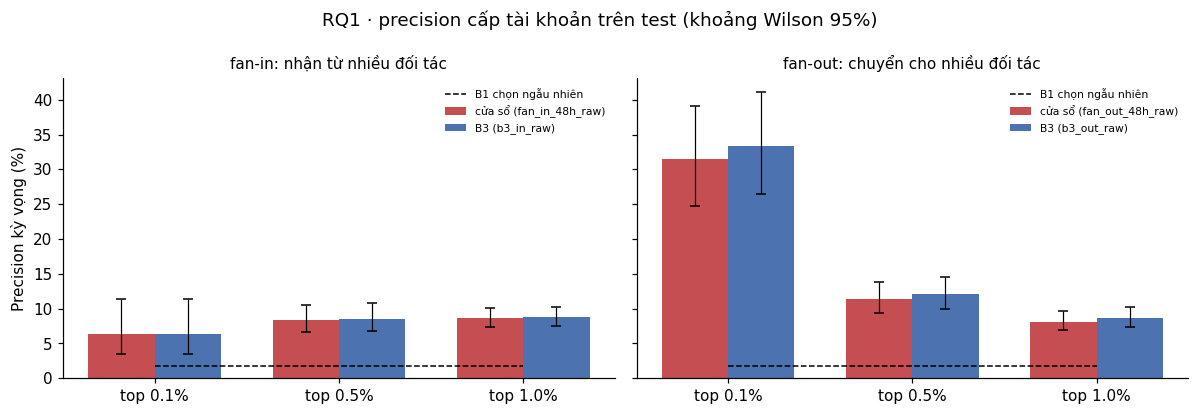

In [10]:
test = acct[acct.segment == "test"]
x = np.arange(len(CFG["budgets"]))
width = 0.36
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, d in zip(axes, CFG["directions"]):
    best = best_by_direction[d]
    for i, (v, col, lab) in enumerate(((best, "#C44E52", f"cửa sổ ({best})"),
                                       (b3_for(best), "#4C72B0", f"B3 ({b3_for(best)})"))):
        r = test[test.variant == v].sort_values("budget")
        ax.bar(x + (i - 0.5) * width, 100 * r.precision_expected, width, color=col, label=lab)
        ax.errorbar(x + (i - 0.5) * width, 100 * r.precision_expected,
                    yerr=[100 * (r.precision_expected - r.wilson_lo), 100 * (r.wilson_hi - r.precision_expected)],
                    fmt="none", ecolor="black", lw=0.8, capsize=3)
    b1 = 100 * test[test.variant == best].sort_values("budget").b1_precision
    ax.plot(x, b1, "k--", lw=1, label="B1 chọn ngẫu nhiên")
    ax.set_xticks(x, [f"top {b:.1%}" for b in CFG["budgets"]])
    ax.set_title("fan-in: nhận từ nhiều đối tác" if d == "in" else "fan-out: chuyển cho nhiều đối tác", fontsize=10)
    ax.legend(fontsize=7, frameon=False)
axes[0].set_ylabel("Precision kỳ vọng (%)")
fig.suptitle("RQ1 · precision cấp tài khoản trên test (khoảng Wilson 95%)")
fig.tight_layout()
fig.savefig(OUT / "rq1_account_precision_test.png", bbox_inches="tight")
plt.show()

## 10. Vì sao cửa sổ thời gian gần như bằng degree

Đoạn test chỉ dài khoảng 4,5 ngày. Nếu một tài khoản gom gần hết đối tác của nó trong vài ngày, thì số đối tác trong cửa sổ 48h gần bằng số đối tác của cả đoạn (B3), và hai điểm chọn ra cùng một danh sách. Ô dưới đo điều đó trên test, cho từng hướng và từng cửa sổ:
- `equal_all_pct`: tỷ lệ ứng viên có fan trong cửa sổ đúng bằng B3;
- `equal_top_pct`: như trên, trong top 1% theo B3;
- `median_span_h_top`: trung vị khoảng thời gian (giờ) từ giao dịch đầu đến giao dịch cuối theo hướng đó của các tài khoản trong top 1% theo B3.

In [11]:
seg = 1
c_test = cand[:, seg]
span = {}
for d in CFG["directions"]:
    center = dst if d == "in" else src
    m = edge_seg == seg
    g = pd.DataFrame({"c": center[m], "t": ts[m]}).groupby("c").t.agg(["min", "max"])
    sp = np.full(N_NODES, np.nan)
    sp[g.index.to_numpy()] = (g["max"] - g["min"]).to_numpy() / 3600
    span[d] = sp
k_top = budget_k(int(c_test.sum()), max(CFG["budgets"]))
rows = []
for d in CFG["directions"]:
    b = b3[d][:, seg]
    top = orders[(f"b3_{d}_raw", seg)][:k_top]
    for W in ALL_WINDOWS:
        f = fan[(d, W)][0][:, seg]
        rows.append({"direction": d, "window_h": W,
                     "equal_all_pct": 100 * np.mean(f[c_test] == b[c_test]),
                     "equal_top_pct": 100 * np.mean(f[top] == b[top]),
                     "median_ratio_top": float(np.median(f[top] / np.maximum(b[top], 1))),
                     "median_span_h_top": float(np.nanmedian(span[d][top]))})
window_vs_degree = pd.DataFrame(rows)
window_vs_degree.to_csv(OUT / "rq1_window_vs_degree.csv", index=False)
display(window_vs_degree.round(2))
seg_hours = seg_days[seg] * 24
for d in CFG["directions"]:
    r48 = window_vs_degree[(window_vs_degree.direction == d) & (window_vs_degree.window_h == 48)].iloc[0]
    print(f"Ý nghĩa (fan-{d}): đoạn test dài {seg_hours:.0f} giờ; tài khoản trong top 1% theo B3 hoạt động trong "
          f"trung vị {r48.median_span_h_top:.1f} giờ, nên cửa sổ 48h đã chứa gần hết đối tác: fan_48h = B3 ở "
          f"{r48.equal_top_pct:.0f}% tài khoản đầu bảng.")

,direction,window_h,equal_all_pct,equal_top_pct,median_ratio_top,median_span_h_top
0,in,24,99.61,93.41,1.0,0.45
1,in,48,99.86,97.25,1.0,0.45
2,in,96,100.00,100.00,1.0,0.45
3,out,24,98.39,88.10,1.0,83.03
4,out,48,99.21,94.56,1.0,83.03
5,out,96,99.98,99.74,1.0,83.03


Ý nghĩa (fan-in): đoạn test dài 107 giờ; tài khoản trong top 1% theo B3 hoạt động trong trung vị 0.5 giờ, nên cửa sổ 48h đã chứa gần hết đối tác: fan_48h = B3 ở 97% tài khoản đầu bảng.
Ý nghĩa (fan-out): đoạn test dài 107 giờ; tài khoản trong top 1% theo B3 hoạt động trong trung vị 83.0 giờ, nên cửa sổ 48h đã chứa gần hết đối tác: fan_48h = B3 ở 95% tài khoản đầu bảng.


## 11. Danh sách cảnh báo và đặc điểm 20 tài khoản đầu bảng trên test

`rq1_alerts_test.csv` liệt kê tài khoản được biến thể tốt nhất mỗi hướng chọn ở mức 1% (seed cố định), kèm điểm, B3, số giao dịch ACH theo hướng đó, số giao dịch trên mỗi đối tác (`tx_per_partner`), cửa sổ đỉnh, loại chủ thể và nhãn, để đọc từng trường hợp khi viết. `rq1_alert_profile_test.csv` tóm tắt theo loại chủ thể: hub lớn nhất là loại tài khoản nào, và tỷ lệ dương của từng loại.

In [12]:
seg = 1
k = budget_k(int(cand[:, seg].sum()), max(CFG["budgets"]))
alert_parts = []
for d in CFG["directions"]:
    v = best_by_direction[d]
    W = int(v.split("_")[2][:-1])
    sel = orders[(v, seg)][:k]
    alert_parts.append(pd.DataFrame({
        "direction": d, "variant": v, "rank": np.arange(1, k + 1),
        "account_key": nodes.account_key.to_numpy()[sel], "entity_type": etype[sel], "peer_group": peer[sel, seg],
        "fan": fan[(d, W)][0][sel, seg], "window_end": pd.to_datetime(fan[(d, W)][1][sel, seg], unit="s"),
        "b3": b3[d][sel, seg], "ach_tx_direction": tx_dir[d][sel, seg],
        "tx_per_partner": tx_dir[d][sel, seg] / np.maximum(b3[d][sel, seg], 1), "A_n": burst[d][sel, seg],
        "is_positive": positive[sel, seg],
    }))
alerts = pd.concat(alert_parts, ignore_index=True)
alerts.to_csv(OUT / "rq1_alerts_test.csv", index=False)

profile = (alerts.assign(top_20=alerts["rank"] <= 20)
           .groupby(["direction", "entity_type"])
           .agg(alerts=("rank", "size"), in_top_20=("top_20", "sum"), positives=("is_positive", "sum"),
                median_tx_per_partner=("tx_per_partner", "median")))
profile["positive_rate_pct"] = 100 * profile.positives / profile.alerts
profile.to_csv(OUT / "rq1_alert_profile_test.csv")
display(profile.round(1))
for d in CFG["directions"]:
    print(f"20 cảnh báo fan-{d} đầu bảng:")
    display(alerts[(alerts.direction == d) & (alerts["rank"] <= 20)]
            [["rank", "account_key", "entity_type", "fan", "b3", "tx_per_partner", "window_end", "is_positive"]])
    top20 = alerts[(alerts.direction == d) & (alerts["rank"] <= 20)]
    print(f"Ý nghĩa: {top20.is_positive.sum()}/20 tài khoản fan-{d} đầu bảng dính rửa tiền; mỗi tài khoản có "
          f"{top20.b3.min()}–{top20.b3.max()} đối tác trong đoạn, trung vị {top20.tx_per_partner.median():.1f} giao dịch "
          f"mỗi đối tác; loại chủ thể: {top20.entity_type.value_counts().to_dict()}.")

alerts  in_top_20  positives  \
direction entity_type                                         
in        Corporation             565          9         47   
          Individual                6          0          0   
          Partnership             554         10         47   
          Sole Proprietorship     438          1         37   
out       Corporation             428          4         34   
          Individual                1          0          0   
          Partnership             528          9         46   
          Sole Proprietorship     606          7         41   

                               median_tx_per_partner  positive_rate_pct  
direction entity_type                                                    
in        Corporation                            1.0                8.3  
          Individual                             1.0                0.0  
          Partnership                            1.0                8.5  
          Sole Proprietorship                    1.0                8.4  
out       Corporation                            3.0                7.9  
          Individual                             1.0                0.0  
          Partnership                            3.0                8.7  
          Sole Proprietorship                    3.3                6.8

20 cảnh báo fan-in đầu bảng:


,rank,account_key,entity_type,fan,b3,tx_per_partner,window_end,is_positive
0,1,4726_808FAF7C0,Partnership,88,88,1.000000,2022-09-08 09:59:00,False
1,2,7042_80640FE10,Partnership,82,82,1.000000,2022-09-08 15:28:00,False
2,3,213005_8050E2560,Partnership,82,82,1.000000,2022-09-07 21:59:00,False
3,4,220271_809FD0970,Partnership,80,80,1.000000,2022-09-10 05:29:00,False
4,5,1420_80032DB60,Partnership,80,80,1.000000,2022-09-09 18:29:00,False
5,6,12_800326F20,Corporation,80,80,1.000000,2022-09-06 18:29:00,False
6,7,227859_813A40B00,Corporation,79,79,1.000000,2022-09-09 08:29:00,False
7,8,1024_80299F770,Corporation,78,78,1.000000,2022-09-10 02:59:00,False
8,9,7042_803382430,Corporation,78,78,1.000000,2022-09-10 21:58:00,False
9,10,14_8007C2A40,Partnership,77,77,1.000000,2022-09-10 11:59:00,False


Ý nghĩa: 1/20 tài khoản fan-in đầu bảng dính rửa tiền; mỗi tài khoản có 73–88 đối tác trong đoạn, trung vị 1.0 giao dịch mỗi đối tác; loại chủ thể: {'Partnership': 10, 'Corporation': 9, 'Sole Proprietorship': 1}.
20 cảnh báo fan-out đầu bảng:


,rank,account_key,entity_type,fan,b3,tx_per_partner,window_end,is_positive
1563,1,11030_80CB65920,Sole Proprietorship,14,14,1.285714,2022-09-08 14:57:00,True
1564,2,23842_8019C0990,Sole Proprietorship,13,13,1.000000,2022-09-09 12:20:00,True
1565,3,13862_8078765D0,Corporation,12,12,1.000000,2022-09-10 17:13:00,True
1566,4,9679_80452D470,Sole Proprietorship,12,17,1.176471,2022-09-08 09:33:00,True
1567,5,5836_80DEE3B40,Sole Proprietorship,12,12,1.000000,2022-09-08 08:24:00,True
1568,6,210431_809BFD6B0,Corporation,11,16,1.000000,2022-09-08 17:13:00,True
1569,7,135981_80F984C70,Partnership,10,10,1.000000,2022-09-09 08:29:00,True
1570,8,21749_80154AAF0,Partnership,10,12,1.083333,2022-09-10 17:44:00,True
1571,9,23289_808839F70,Partnership,10,13,1.000000,2022-09-09 21:05:00,True
1572,10,18196_80B1BF360,Sole Proprietorship,9,10,1.200000,2022-09-07 14:23:00,True


Ý nghĩa: 19/20 tài khoản fan-out đầu bảng dính rửa tiền; mỗi tài khoản có 7–17 đối tác trong đoạn, trung vị 1.0 giao dịch mỗi đối tác; loại chủ thể: {'Partnership': 9, 'Sole Proprietorship': 7, 'Corporation': 4}.


## 12. Kết luận và trả lời câu hỏi nghiên cứu

Tiêu chí như bảng ở đầu notebook, áp cho **từng hướng** (biến thể tốt nhất của hướng đó so với B3 tương ứng), dùng `precision_expected`. Kết luận chính là của biến thể chính đã chốt trên dev; hướng còn lại được báo cáo cùng tiêu chí.

In [13]:
def wins(variant, seg_name):
    a = acct[(acct.segment == seg_name) & (acct.variant == variant)].set_index("budget")
    b = acct[(acct.segment == seg_name) & (acct.variant == b3_for(variant))].set_index("budget")
    return a.wilson_lo > a.b1_precision, a.precision_expected > b.precision_expected


def verdict_for(variant):
    need_n = CFG["min_budgets_to_win"]
    t_b1, t_b3 = wins(variant, "test")
    d_b1, d_b3 = wins(variant, "dev")
    n_pos_test = int(seg_summary.loc[1, "positive_candidates"])
    if n_pos_test < CFG["min_positives"]:
        return "Dừng", f"chỉ {n_pos_test} tài khoản dương trong test", t_b1, t_b3
    if (t_b1 & t_b3).sum() >= need_n and (d_b1 & d_b3).sum() >= need_n:
        return "Đào sâu", f"thắng B1 và B3 ở {(t_b1 & t_b3).sum()}/3 mức trên test và {(d_b1 & d_b3).sum()}/3 trên dev", t_b1, t_b3
    if t_b1.sum() >= need_n:
        if (t_b1 & t_b3).sum() < need_n:
            return "Điều chỉnh", f"thắng B1 ở {t_b1.sum()}/3 mức nhưng chỉ thắng B3 ở {(t_b1 & t_b3).sum()}/3 trên test", t_b1, t_b3
        return "Điều chỉnh", "thắng B1 và B3 trên test nhưng không ổn định trên dev", t_b1, t_b3
    return "Dừng", f"chỉ thắng B1 ở {t_b1.sum()}/3 mức trên test", t_b1, t_b3


def metric(v, b, col="precision_expected", seg_name="test"):
    return float(acct[(acct.segment == seg_name) & (acct.variant == v) & (acct.budget == b)][col].iloc[0])


def ap(v, seg_name="test"):
    return float(acct[(acct.segment == seg_name) & (acct.variant == v)].ap.iloc[0])


by_direction = {}
for d in CFG["directions"]:
    v = best_by_direction[d]
    verdict, reason, t_b1, t_b3 = verdict_for(v)
    by_direction[d] = {
        "variant": v, "b3": b3_for(v), "verdict": verdict, "reason": reason,
        "test_beats_b1_by_budget": {str(k): bool(x) for k, x in t_b1.items()},
        "test_beats_b3_by_budget": {str(k): bool(x) for k, x in t_b3.items()},
        "test_precision_expected": {str(b): round(metric(v, b), 4) for b in CFG["budgets"]},
        "test_b3_precision_expected": {str(b): round(metric(b3_for(v), b), 4) for b in CFG["budgets"]},
        "test_overlap_with_b3": {str(b): round(metric(v, b, "overlap_with_b3"), 3) for b in CFG["budgets"]},
    }

bi, bo = best_by_direction["in"], best_by_direction["out"]
answers = {
    "fan_in_vs_fan_out": "; ".join(f"top {b:.1%}: fan-in {metric(bi, b):.2%}, fan-out {metric(bo, b):.2%}"
                                    for b in CFG["budgets"]) + f" (AP test: fan-in {ap(bi):.4f}, fan-out {ap(bo):.4f})",
    "window_vs_b3": {d: "; ".join(f"top {b:.1%}: {metric(by_direction[d]['variant'], b):.2%} vs B3 "
                                   f"{metric(by_direction[d]['b3'], b):.2%}" for b in CFG["budgets"])
                     for d in CFG["directions"]},
    "burstiness_tie_break": "; ".join(f"top {b:.1%}: {metric(primary + '+burst', b):.2%} vs {metric(primary, b):.2%}"
                                      for b in CFG["budgets"]),
    "window_96h": "; ".join(f"{v}: AP test {ap(v):.4f}" for v in report_variants if "_96h_" in v),
}
decision = {"primary": primary, "hash": frozen["hash"],
            "verdict": by_direction[primary.split("_")[1]]["verdict"],
            "reason": by_direction[primary.split("_")[1]]["reason"],
            "by_direction": by_direction, "answers": answers,
            "note_tail": "tail segment reported only as sensitivity; it is not used for any choice"}
(OUT / "rq1_decision.json").write_text(json.dumps(decision, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"KẾT LUẬN (biến thể chính {primary}): {decision['verdict']} · {decision['reason']}")
for d in CFG["directions"]:
    print(f"  fan-{d} ({by_direction[d]['variant']}): {by_direction[d]['verdict']} · {by_direction[d]['reason']}")
print("\nFan-in hay fan-out:", answers["fan_in_vs_fan_out"])
for d in CFG["directions"]:
    print(f"Cửa sổ so với B3, fan-{d}:", answers["window_vs_b3"][d])
print("Burstiness để phá đồng hạng:", answers["burstiness_tie_break"])
print("Cửa sổ 96h:", answers["window_96h"])

KẾT LUẬN (biến thể chính fan_in_48h_raw): Điều chỉnh · thắng B1 ở 3/3 mức nhưng chỉ thắng B3 ở 0/3 trên test
  fan-in (fan_in_48h_raw): Điều chỉnh · thắng B1 ở 3/3 mức nhưng chỉ thắng B3 ở 0/3 trên test
  fan-out (fan_out_48h_raw): Điều chỉnh · thắng B1 ở 3/3 mức nhưng chỉ thắng B3 ở 0/3 trên test

Fan-in hay fan-out: top 0.1%: fan-in 6.41%, fan-out 31.50%; top 0.5%: fan-in 8.39%, fan-out 11.39%; top 1.0%: fan-in 8.59%, fan-out 8.13% (AP test: fan-in 0.0378, fan-out 0.0409)
Cửa sổ so với B3, fan-in: top 0.1%: 6.41% vs B3 6.41%; top 0.5%: 8.39% vs B3 8.58%; top 1.0%: 8.59% vs B3 8.78%
Cửa sổ so với B3, fan-out: top 0.1%: 31.50% vs B3 33.32%; top 0.5%: 11.39% vs B3 12.06%; top 1.0%: 8.13% vs B3 8.69%
Burstiness để phá đồng hạng: top 0.1%: 6.41% vs 6.41%; top 0.5%: 8.07% vs 8.39%; top 1.0%: 8.45% vs 8.59%
Cửa sổ 96h: fan_in_96h_raw: AP test 0.0387; fan_out_96h_raw: AP test 0.0440


## Phụ lục A. Đánh giá cấp giao dịch

Hub là một **tài khoản**, không phải một giao dịch: phần lớn giao dịch của một hub là bình thường. Vì vậy kết quả chính của RQ1 là cấp tài khoản (mục 9); phần này chỉ là phụ lục.


- **Cửa sổ:** với mỗi tài khoản được chọn, gắn cờ các giao dịch ACH theo đúng hướng (vào cho fan-in, ra cho fan-out) nằm trong **cửa sổ đỉnh** $[\mathrm{end}-W, \mathrm{end}]$.
- **B3:** gắn cờ mọi giao dịch ACH theo hướng đó của tài khoản trong đoạn.
- Gộp theo `transaction_id`. Mẫu số = mọi giao dịch của đoạn trong file gốc (gồm self-loop và dòng trùng).
- Đối chứng: chọn ngẫu nhiên (tỷ lệ nền), ACH-only (mọi giao dịch ACH), và mẫu ACH ngẫu nhiên có cùng số cảnh báo với biến thể cửa sổ.
- Dùng thứ tự với seed cố định (cấp giao dịch không có công thức kỳ vọng đơn giản).

In [14]:
eid = edges.transaction_id.to_numpy()


def project(variant, seg, k):
    order = orders[(variant, seg)]
    sel = np.zeros(N_NODES, dtype=bool)
    sel[order[:k]] = True
    parts = variant.split("_")
    direction = parts[1]
    center = dst if direction == "in" else src
    m = sel[center] & (edge_seg == seg)
    if parts[0] == "fan":
        W = int(parts[2][:-1])
        end = fan[(direction, W)][1][:, seg][center]
        m &= (ts <= end) & (ts >= end - W * 3600)
    return np.unique(eid[m])


rng = np.random.default_rng(CFG["seed"])
tx_rows = []
for seg in range(n_seg):
    lab_s = labels[labels.seg == seg]
    n_tx, n_ill = len(lab_s), int(lab_s.is_laundering.sum())
    ach_s = lab_s[lab_s.is_ach]
    n_ach, tp_ach = len(ach_s), int(ach_s.is_laundering.sum())
    base = {"segment": SEGMENTS[seg], "n_transactions": n_tx, "n_laundering": n_ill}
    tx_rows.append({**base, "method": "Random (expected)", "precision": n_ill / n_tx if n_tx else np.nan})
    tx_rows.append({**base, "method": "ACH-only", "flagged": n_ach, "tp": tp_ach,
                    "precision": tp_ach / n_ach if n_ach else np.nan, "recall": tp_ach / n_ill if n_ill else np.nan})
    n_cand = int(cand[:, seg].sum())
    for b in CFG["budgets"]:
        k = budget_k(n_cand, b)
        for v in key_variants:
            ids = project(v, seg, k)
            tp = int(tx_label.reindex(ids).fillna(0).sum())
            lo, hi = wilson(tp, len(ids))
            tx_rows.append({**base, "method": f"{role[v]} [{v}]", "budget": b, "flagged": len(ids), "tp": tp,
                            "precision": tp / len(ids) if len(ids) else np.nan, "wilson_lo": lo, "wilson_hi": hi,
                            "recall": tp / n_ill if n_ill else np.nan})
            if v.startswith("fan_") and n_ach:
                m = min(len(ids), n_ach)
                tp_r = int(ach_s.is_laundering.to_numpy()[rng.choice(n_ach, m, replace=False)].sum())
                tx_rows.append({**base, "method": f"Random ACH sample, same size as [{v}]", "budget": b,
                                "flagged": m, "tp": tp_r, "precision": tp_r / m if m else np.nan,
                                "recall": tp_r / n_ill if n_ill else np.nan})
txm = pd.DataFrame(tx_rows)
txm.to_csv(OUT / "rq1_transaction_metrics.csv", index=False)
display(txm[txm.segment == "test"].round(5))

,segment,n_transactions,n_laundering,method,precision,flagged,tp,recall,budget,wilson_lo,wilson_hi
20,test,2042038,2250,Random (expected),0.00110,NaN,NaN,NaN,NaN,NaN,NaN
21,test,2042038,2250,ACH-only,0.00741,262486.0,1946.0,0.86489,NaN,NaN,NaN
22,test,2042038,2250,primary · best fan-in [fan_in_48h_raw],0.00110,9110.0,10.0,0.00444,0.001,0.00060,0.00202
23,test,2042038,2250,"Random ACH sample, same size as [fan_in_48h_raw]",0.00790,9110.0,72.0,0.03200,0.001,NaN,NaN
24,test,2042038,2250,B3 fan-in [b3_in_raw],0.00109,9188.0,10.0,0.00444,0.001,0.00059,0.00200
25,test,2042038,2250,best fan-out [fan_out_48h_raw],0.24557,1185.0,291.0,0.12933,0.001,0.22191,0.27087
26,test,2042038,2250,"Random ACH sample, same size as [fan_out_48h_raw]",0.00506,1185.0,6.0,0.00267,0.001,NaN,NaN
27,test,2042038,2250,B3 fan-out [b3_out_raw],0.15446,2266.0,350.0,0.15556,0.001,0.14016,0.16992
28,test,2042038,2250,primary · best fan-in [fan_in_48h_raw],0.00357,21589.0,77.0,0.03422,0.005,0.00285,0.00446
29,test,2042038,2250,"Random ACH sample, same size as [fan_in_48h_raw]",0.00801,21589.0,173.0,0.07689,0.005,NaN,NaN


## Phụ lục B. Burstiness: độ phủ và tỷ lệ dương

In [15]:
brows = []
for seg in range(n_seg):
    for d in CFG["directions"]:
        c = cand[:, seg]
        has = c & ~np.isnan(burst[d][:, seg])
        pos_has, neg_has = has & positive[:, seg], has & ~positive[:, seg]
        brows.append({"segment": SEGMENTS[seg], "direction": d, "candidates": int(c.sum()),
                      "with_A_n": int(has.sum()), "coverage_pct": 100 * has.sum() / max(c.sum(), 1),
                      "positive_rate_with_A_n_pct": 100 * positive[has, seg].mean() if has.any() else np.nan,
                      "positive_rate_without_pct": 100 * positive[c & ~has, seg].mean() if (c & ~has).any() else np.nan,
                      "median_A_n_positive": np.nanmedian(burst[d][pos_has, seg]) if pos_has.any() else np.nan,
                      "median_A_n_negative": np.nanmedian(burst[d][neg_has, seg]) if neg_has.any() else np.nan})
bt = pd.DataFrame(brows)
bt.to_csv(OUT / "rq1_burstiness.csv", index=False)
display(bt.round(3))

,segment,direction,candidates,with_A_n,coverage_pct,positive_rate_with_A_n_pct,positive_rate_without_pct,median_A_n_positive,median_A_n_negative
0,dev,in,209931,13680,6.516,2.412,1.306,-0.024,-0.343
1,dev,out,209931,13276,6.324,1.687,1.358,-0.162,-0.267
2,test,in,156284,4126,2.640,5.550,1.668,0.008,-0.098
3,test,out,156284,6193,3.963,2.890,1.724,-0.145,-0.193
4,tail,in,716,19,2.654,100.000,99.857,0.118,NaN
5,tail,out,716,21,2.933,100.000,99.856,-0.003,NaN


In [16]:
print("Các file trong", OUT)
for f in sorted(OUT.iterdir()):
    print("  ", f.name)

Các file trong D:\KLTN\reports\rq1
   rq1_account_metrics.csv
   rq1_account_precision_test.png
   rq1_alert_profile_test.csv
   rq1_alerts_test.csv
   rq1_burstiness.csv
   rq1_decision.json
   rq1_frozen_choice.json
   rq1_segments.csv
   rq1_transaction_metrics.csv
   rq1_variant_selection_dev.csv
   rq1_window_vs_degree.csv
